# Detección de lavado de dinero con PySpark y MLlib
## Modulo 6 Utilización, procesamiento y visualización de grandes volúmenes de datos (Portafolio Análisis)

**Objetivo:** entrenar un modelo de clasificación que identifique transacciones bancarias sospechosas de lavado de dinero, usando Spark para procesar millones de registros, y visualizar los resultados en un tablero de **Tableau Public**.

**Base de datos:** [IBM Transactions for Anti Money Laundering (AML)](https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml), un conjunto sintético generado por IBM que simula transacciones entre bancos. Usamos el archivo `LI-Small_Trans.csv` (**~6.9 millones de transacciones, 0.65 GB**). La etiqueta `Is Laundering` indica si la transacción forma parte de un esquema de lavado.

**Link de google colab (donde se corrió el proyecto):** https://colab.research.google.com/drive/16Nn5N_nu5QdgbzdqGjvPEX5UDoiY0BP4?usp=sharing

**Flujo del proyecto**

1. Preparación del ambiente en Colab (PySpark)
2. Selección, descarga y carga de la base de datos
3. Análisis exploratorio y calidad de datos (nulos, duplicados, rangos, desbalance)
4. Ingeniería de características
5. División de datos y balanceo del entrenamiento
6. Entrenamiento con MLlib (Random Forest + validación cruzada)
7. Evaluación con métricas adecuadas para clases desbalanceadas
8. Predicciones sobre datos nuevos
9. Exportación de datos para Tableau y eficiencia del procesamiento
10. Tablero en Tableau Public y decisiones que apoya
11. Conclusiones

## 1. Preparación del ambiente de trabajo en Colab

Colab ya trae Java, así que basta con instalar `pyspark` (motor de Spark para Python) y `kagglehub` (descarga de datasets de Kaggle). Después creamos una `SparkSession`, que es el punto de entrada a Spark. En Colab Spark corre en **modo local**: usa todos los núcleos de la máquina virtual como si fueran nodos de un clúster.

In [4]:
!pip install kagglehub

In [5]:
!pip install pyspark

In [6]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, VectorAssembler
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.functions import vector_to_array

# =========================================================
# 1. Inicializar SparkSession
# =========================================================
spark = (SparkSession.builder
         .appName("RetoBigData")
         .config("spark.driver.memory", "8g")           # Colab tiene ~12 GB de RAM
         .config("spark.sql.shuffle.partitions", "32")  # pocas particiones: solo hay 2 núcleos
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print(f"Spark {spark.version} listo | núcleos disponibles: {spark.sparkContext.defaultParallelism}")

Spark 4.0.5 listo | núcleos disponibles: 2


## 2. Selección y descarga de la base de datos

Elegimos el dataset de IBM para AML porque:

* Tiene **gran volumen** (de 5 a 180 millones de transacciones según la versión); la versión *Small* ya supera los 6.9 millones de filas, imposible de manejar cómodamente con pandas.
* Tiene una etiqueta confiable (`Is Laundering`), algo que casi no existe en datos bancarios reales.
* Representa un problema real de clasificación con **clases muy desbalanceadas**.

Los archivos `LI` (*Low Illicit*) tienen menos casos de lavado que los `HI` (*High Illicit*). Entrenamos con `LI-Small` y más adelante usamos `HI-Small` como conjunto de prueba **completamente nuevo**.

| Archivo | Uso | Filas | Tamaño |
|---|---|---|---|
| `LI-Small_Trans.csv` | Entrenamiento, validación y prueba | 6,924,049 | 0.65 GB |
| `HI-Small_Trans.csv` | Datos nuevos para predicciones | ~5.08 millones | 0.48 GB |
| **Total** | | **~12 millones** | **1.13 GB** |

In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ealtman2019/ibm-transactions-for-anti-money-laundering-aml")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'ibm-transactions-for-anti-money-laundering-aml' dataset.
Path to dataset files: /kaggle/input/ibm-transactions-for-anti-money-laundering-aml


In [8]:
import os

# Listar los archivos disponibles en la ruta del dataset descargado
print("Archivos descargados:")
for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))

Archivos descargados:
/kaggle/input/ibm-transactions-for-anti-money-laundering-aml/HI-Medium_accounts.csv
/kaggle/input/ibm-transactions-for-anti-money-laundering-aml/LI-Small_Trans.csv
/kaggle/input/ibm-transactions-for-anti-money-laundering-aml/HI-Large_accounts.csv
/kaggle/input/ibm-transactions-for-anti-money-laundering-aml/HI-Large_Trans.csv
/kaggle/input/ibm-transactions-for-anti-money-laundering-aml/HI-Medium_Trans.csv
/kaggle/input/ibm-transactions-for-anti-money-laundering-aml/LI-Medium_accounts.csv
/kaggle/input/ibm-transactions-for-anti-money-laundering-aml/HI-Small_Patterns.txt
/kaggle/input/ibm-transactions-for-anti-money-laundering-aml/HI-Medium_Patterns.txt
/kaggle/input/ibm-transactions-for-anti-money-laundering-aml/HI-Small_accounts.csv
/kaggle/input/ibm-transactions-for-anti-money-laundering-aml/LI-Medium_Trans.csv
/kaggle/input/ibm-transactions-for-anti-money-laundering-aml/HI-Large_Patterns.txt
/kaggle/input/ibm-transactions-for-anti-money-laundering-aml/LI-Medium_P

In [ ]:
# Tamaño en disco de los dos archivos que usa el notebook
for f in ["LI-Small_Trans.csv", "HI-Small_Trans.csv"]:
    print(f, f"{os.path.getsize(f'{path}/{f}') / 1e9:.2f} GB")

LI-Small_Trans.csv 0.65 GB
HI-Small_Trans.csv 0.48 GB


### Carga y Exploración de Datos con PySpark

Ahora cargaremos uno de los archivos principales de transacciones para explorar su esquema y el volumen de registros.

In [9]:
# Buscamos los archivos CSV de transacciones dentro del directorio descargado
import glob
csv_files = glob.glob(f"{path}/**/*Trans.csv", recursive=True)

if csv_files:
    # Seleccionamos un archivo de transacciones (por ejemplo, el primero de tamaño manejable para la demo)
    dataset_path = [f for f in csv_files if "LI-Small_Trans" in f][0]
    print(f"Cargando archivo de transacciones: {dataset_path}")

    # Leemos el archivo CSV con PySpark
    df = spark.read.csv(dataset_path, header=True, inferSchema=True)

    # Mostramos el número total de registros para comprobar el volumen
    print(f"Total de registros: {df.count()}")

    # Mostramos el esquema de las columnas
    df.printSchema()

    # Mostramos las primeras 5 filas de manera elegante
    df.show(5, truncate=True)
else:
    print("No se encontraron archivos de transacciones CSV en la ruta especificada.")

Cargando archivo de transacciones: /kaggle/input/ibm-transactions-for-anti-money-laundering-aml/LI-Small_Trans.csv
Total de registros: 6924049
root
 |-- Timestamp: string (nullable = true)
 |-- From Bank: integer (nullable = true)
 |-- Account2: string (nullable = true)
 |-- To Bank: integer (nullable = true)
 |-- Account4: string (nullable = true)
 |-- Amount Received: double (nullable = true)
 |-- Receiving Currency: string (nullable = true)
 |-- Amount Paid: double (nullable = true)
 |-- Payment Currency: string (nullable = true)
 |-- Payment Format: string (nullable = true)
 |-- Is Laundering: integer (nullable = true)

+----------------+---------+---------+-------+---------+---------------+------------------+-----------+----------------+--------------+-------------+
|       Timestamp|From Bank| Account2|To Bank| Account4|Amount Received|Receiving Currency|Amount Paid|Payment Currency|Payment Format|Is Laundering|
+----------------+---------+---------+-------+---------+------------

## 3. Análisis exploratorio y calidad de datos

### 3.1 Calidad de los datos

Antes de modelar revisamos:

* **Valores nulos o vacíos** por columna (y `NaN` en las numéricas).
* **Filas duplicadas exactas**: mismas cuentas, bancos, monto, moneda, formato y minuto.
* **Rangos y consistencia**: montos negativos o en cero, transacciones con la misma moneda pero distinto monto pagado y recibido, y periodo que cubren los datos.
* **Cardinalidad**: cuántas cuentas, bancos, monedas y formatos distintos hay.

Todo se calcula con agregaciones de Spark, que recorren los millones de filas de forma distribuida.

In [10]:
n_total = df.count()
print(f"Filas: {n_total:,} | Columnas: {len(df.columns)}\n")

# 1. Nulos / vacíos / NaN por columna, en una sola pasada sobre los datos
exprs = []
for c, tipo in df.dtypes:
    cond = F.col(c).isNull()
    if tipo == "string":
        cond = cond | (F.trim(F.col(c)) == "")
    elif tipo == "double":
        cond = cond | F.isnan(F.col(c))
    exprs.append(F.sum(cond.cast("int")).alias(c))
nulos = df.agg(*exprs).first().asDict()
print("Nulos o vacíos por columna:")
for c, n in nulos.items():
    print(f"  {c:<20} {n:>10,}  ({n / n_total:.4%})")

# 2. Duplicados exactos
duplicados = df.groupBy(df.columns).count().filter(F.col("count") > 1).cache()
r = duplicados.agg(
    F.sum(F.col("count") - 1).alias("sobrantes"),
    F.sum(F.when(F.col("Is Laundering") == 1, F.col("count") - 1).otherwise(0)).alias("de_lavado")).first()
n_dup, n_dup_lav = (r["sobrantes"] or 0), (r["de_lavado"] or 0)
print(f"\nFilas duplicadas exactas (copias sobrantes): {n_dup:,} ({n_dup / n_total:.4%}), de ellas {n_dup_lav:,} marcadas como lavado")
if n_dup:
    print("Ejemplos de filas repetidas:")
    duplicados.orderBy(F.desc("count")).show(5, truncate=False)

Filas: 6,924,049 | Columnas: 11

Nulos o vacíos por columna:
  Timestamp                     0  (0.0000%)
  From Bank                     0  (0.0000%)
  Account2                      0  (0.0000%)
  To Bank                       0  (0.0000%)
  Account4                      0  (0.0000%)
  Amount Received               0  (0.0000%)
  Receiving Currency            0  (0.0000%)
  Amount Paid                   0  (0.0000%)
  Payment Currency              0  (0.0000%)
  Payment Format                0  (0.0000%)
  Is Laundering                 0  (0.0000%)

Filas duplicadas exactas (copias sobrantes): 8 (0.0001%), de ellas 0 marcadas como lavado
Ejemplos de filas repetidas:
+----------------+---------+---------+-------+---------+---------------+------------------+-----------+----------------+--------------+-------------+-----+
|Timestamp       |From Bank|Account2 |To Bank|Account4 |Amount Received|Receiving Currency|Amount Paid|Payment Currency|Payment Format|Is Laundering|count|
+-----------

In [11]:
# 3. Rangos y consistencia
print("Estadísticas de los montos:")
df.select("Amount Paid", "Amount Received").summary("min", "25%", "50%", "75%", "max", "mean").show()

n_no_positivos = df.filter((F.col("Amount Paid") <= 0) | (F.col("Amount Received") <= 0)).count()
n_inconsistentes = df.filter((F.col("Payment Currency") == F.col("Receiving Currency")) &
                             (F.abs(F.col("Amount Paid") - F.col("Amount Received")) > 0.01)).count()
print(f"Montos negativos o en cero                    : {n_no_positivos:,}")
print(f"Misma moneda pero distinto monto pagado/recibido: {n_inconsistentes:,}")

ts = F.to_timestamp("Timestamp", "yyyy/MM/dd HH:mm")
df.agg(F.min(ts).alias("primera_transaccion"), F.max(ts).alias("ultima_transaccion")).show()

# 4. Cardinalidad (conteo aproximado, mucho más rápido en millones de filas)
print("Valores distintos (aprox.):")
df.agg(F.approx_count_distinct("Account2").alias("cuentas_origen"),
       F.approx_count_distinct("Account4").alias("cuentas_destino"),
       F.approx_count_distinct("From Bank").alias("bancos"),
       F.countDistinct("Payment Currency").alias("monedas"),
       F.countDistinct("Payment Format").alias("formatos")).show()

# 5. Limpieza: quitamos duplicados exactos (los nulos se filtran en construir_features)
df_limpio = df.dropDuplicates().cache()
print(f"Filas después de eliminar duplicados: {df_limpio.count():,} (se quitaron {n_total - df_limpio.count():,})")
duplicados.unpersist()

Estadísticas de los montos:
+-------+-------------------+-------------------+
|summary|        Amount Paid|    Amount Received|
+-------+-------------------+-------------------+
|    min|             1.0E-6|             1.0E-6|
|    25%|              175.4|             174.18|
|    50%|            1399.17|            1397.25|
|    75%|           12226.39|           12291.54|
|    max|3.64485366274695E12|3.64485366274695E12|
|   mean|  4676035.972670585|  6324066.605182441|
+-------+-------------------+-------------------+

Montos negativos o en cero                    : 0
Misma moneda pero distinto monto pagado/recibido: 0
+-------------------+-------------------+
|primera_transaccion| ultima_transaccion|
+-------------------+-------------------+
|2022-09-01 00:00:00|2022-09-17 15:28:00|
+-------------------+-------------------+

Valores distintos (aprox.):
+--------------+---------------+------+-------+--------+
|cuentas_origen|cuentas_destino|bancos|monedas|formatos|
+--------------+

DataFrame[Timestamp: string, From Bank: int, Account2: string, To Bank: int, Account4: string, Amount Received: double, Receiving Currency: string, Amount Paid: double, Payment Currency: string, Payment Format: string, Is Laundering: int, count: bigint]

**Decisiones de limpieza**

* **Duplicados:** se eliminan las filas idénticas en todas sus columnas. Como el `Timestamp` solo llega al minuto, no podemos distinguir un pago repetido legítimo de un registro cargado dos veces. Además, si dejamos copias exactas, la misma fila puede caer en entrenamiento y en prueba, y el modelo se evaluaría con datos que ya vio (*data leakage*).
* **Nulos:** las filas sin fecha, monto, formato o cuentas se descartan en `construir_features`, porque sin esos campos no se pueden calcular las variables.
* **Montos:** la diferencia entre monto pagado y recibido con distinta moneda es esperable (tipo de cambio). Con la misma moneda debería ser cero.

**Resultados de la revisión**

* **Nulos:** ninguna de las 11 columnas tiene valores nulos, vacíos ni `NaN`.
* **Duplicados:** solo 8 filas repetidas de 6,924,049 (0.0001%). Todas son pagos en Bitcoin por montos mínimos (0.000001 a 0.000007 BTC) y ninguna es lavado. Se eliminaron y quedan **6,924,041 transacciones**.
* **Montos:** no hay negativos ni ceros. La distribución está muy sesgada: la mediana es 1,399, pero el promedio es 4.7 millones y el máximo 3.6 billones (3.64 × 10¹²), porque se mezclan 15 monedas con valores muy distintos (de Bitcoin a Yen). Por eso más adelante se agrega `log_monto`.
* **Consistencia:** cuando la moneda pagada y la recibida son iguales, los montos siempre coinciden (0 inconsistencias). La diferencia entre el promedio pagado y el recibido viene de las transacciones con cambio de divisa.
* **Periodo:** del 1 al 17 de septiembre de 2022, pero casi toda la actividad ocurre entre el 1 y el 10. Del 11 al 17 solo hay 223 transacciones y 134 de ellas (60%) son lavado. Probablemente es un efecto de la simulación de IBM: la generación de transacciones normales termina el día 10 y solo se completan los esquemas de lavado que quedaron abiertos. No afecta al modelo porque la fecha no se usa como variable, pero sí hay que considerarlo al graficar por día.
* **Cardinalidad:** ~694 mil cuentas de origen, ~575 mil cuentas de destino, ~40.5 mil bancos, 15 monedas y 7 formatos de pago. Con tantas cuentas no tiene sentido usar el ID como variable; por eso se resumen en variables de comportamiento por cuenta.

**Conclusión:** los datos están limpios y la única limpieza necesaria fue quitar 8 duplicados.

### 3.2 El problema del desbalance


Hay que ver cuántas transacciones son lavado. Si la clase positiva es muy rara, un modelo que **siempre** responda "no es lavado" tendrá una exactitud altísima sin detectar nada. Por eso la *accuracy* no sirve como métrica principal aquí.

In [12]:
total = df_limpio.count()

print("Distribución de la etiqueta:")
(df_limpio.groupBy("Is Laundering").count()
   .withColumn("porcentaje", F.round(F.col("count") / total * 100, 4))
   .show())

print("Tasa de lavado por formato de pago:")
(df_limpio.groupBy("Payment Format")
   .agg(F.count("*").alias("transacciones"),
        F.sum("Is Laundering").alias("lavado"),
        F.round(F.avg("Is Laundering") * 100, 3).alias("tasa_lavado_%"))
   .orderBy(F.desc("tasa_lavado_%"))
   .show())

print("Tasa de lavado por moneda de pago:")
(df_limpio.groupBy("Payment Currency")
   .agg(F.count("*").alias("transacciones"),
        F.round(F.avg("Is Laundering") * 100, 3).alias("tasa_lavado_%"))
   .orderBy(F.desc("tasa_lavado_%"))
   .show(truncate=False))

Distribución de la etiqueta:
+-------------+-------+----------+
|Is Laundering|  count|porcentaje|
+-------------+-------+----------+
|            1|   3565|    0.0515|
|            0|6920476|   99.9485|
+-------------+-------+----------+

Tasa de lavado por formato de pago:
+--------------+-------------+------+-------------+
|Payment Format|transacciones|lavado|tasa_lavado_%|
+--------------+-------------+------+-------------+
|           ACH|       796580|  2611|        0.328|
|       Bitcoin|       309201|   110|        0.036|
|          Cash|       655688|   124|        0.019|
|        Cheque|      2503158|   459|        0.018|
|   Credit Card|      1780389|   261|        0.015|
|          Wire|       228567|     0|          0.0|
|  Reinvestment|       650458|     0|          0.0|
+--------------+-------------+------+-------------+

Tasa de lavado por moneda de pago:
+-----------------+-------------+-------------+
|Payment Currency |transacciones|tasa_lavado_%|
+-----------------+-

**Observaciones**

* Solo **3,565 de 6,924,041 transacciones son lavado (0.0515%)**, es decir, 1 de cada ~1,940. Un modelo que siempre responda "normal" tendría 99.95% de exactitud: exactamente lo que le pasó a la primera versión del modelo.
* **ACH concentra el 73% del lavado** (2,611 casos), con una tasa de 0.328%, unas 6 veces el promedio. Le siguen Cheque (459), Credit Card (261), Cash (124) y Bitcoin (110). **Wire y Reinvestment no tienen ningún caso.** El formato de pago es una variable muy informativa.
* Por moneda, la tasa va de 0.033% (Rupee) a 0.064% (Euro). Las diferencias son pequeñas, así que la moneda aporta poca información por sí sola.

## 4. Ingeniería de características

La primera versión del modelo solo usaba `Amount Paid` y `Payment Format`, y con esa información el Random Forest asignaba **la misma probabilidad a todas las transacciones** (siempre predecía "no lavado"). Para darle señal al modelo creamos variables que describen tanto la transacción como el comportamiento de las cuentas:

| Variable | Qué captura |
|---|---|
| `hora`, `dia_semana` | Momento de la transacción |
| `log_monto` | Monto en escala logarítmica (los montos van de centavos a millones) |
| `misma_cuenta`, `mismo_banco`, `misma_moneda` | Auto-transferencias, transferencias internas, cambio de divisa |
| `monto_redondo` | Montos múltiplos de 100 |
| `tx_enviadas`, `destinos_distintos` | Cuántas transacciones envía la cuenta origen y a cuántas cuentas (patrón *fan-out*) |
| `tx_recibidas`, `origenes_distintos` | Cuántas recibe la cuenta destino y de cuántas cuentas (patrón *fan-in*) |
| `ratio_monto_prom` | Qué tan grande es el monto respecto al promedio de esa cuenta |
| `payment_format`, `payment_currency`, `receiving_currency` | Variables categóricas (se indexan con `StringIndexer`) |

Las variables por cuenta se calculan con agregaciones de Spark (`groupBy` + `join`) sobre todas las transacciones del archivo y **no usan la etiqueta**, así que no filtran información del resultado. Todo se agrupa en una función para aplicar exactamente la misma transformación a cualquier conjunto de datos nuevo.

In [13]:
def construir_features(df_raw):
    # Convierte el CSV crudo del dataset IBM AML en una tabla con las variables del modelo.
    tiene_etiqueta = "Is Laundering" in df_raw.columns
    d = df_raw.select(
        F.to_timestamp("Timestamp", "yyyy/MM/dd HH:mm").alias("ts"),
        F.col("From Bank").alias("from_bank"),
        F.col("Account2").alias("from_account"),
        F.col("To Bank").alias("to_bank"),
        F.col("Account4").alias("to_account"),
        F.col("Amount Received").alias("amount_received"),
        F.col("Receiving Currency").alias("receiving_currency"),
        F.col("Amount Paid").alias("amount_paid"),
        F.col("Payment Currency").alias("payment_currency"),
        F.col("Payment Format").alias("payment_format"),
        (F.col("Is Laundering").cast("double") if tiene_etiqueta
         else F.lit(None).cast("double")).alias("label"),
    ).na.drop(subset=["ts", "amount_paid", "payment_format", "from_account", "to_account"])

    d = (d.withColumn("fecha", F.to_date("ts"))
          .withColumn("hora", F.hour("ts"))
          .withColumn("dia_semana", F.dayofweek("ts"))
          .withColumn("log_monto", F.log1p("amount_paid"))
          .withColumn("misma_cuenta", (F.col("from_account") == F.col("to_account")).cast("int"))
          .withColumn("mismo_banco", (F.col("from_bank") == F.col("to_bank")).cast("int"))
          .withColumn("misma_moneda", (F.col("payment_currency") == F.col("receiving_currency")).cast("int"))
          .withColumn("monto_redondo", ((F.col("amount_paid") % 100) == 0).cast("int")))

    # Comportamiento de las cuentas (sin usar la etiqueta)
    salidas = d.groupBy("from_account").agg(
        F.count("*").alias("tx_enviadas"),
        F.countDistinct("to_account").alias("destinos_distintos"),
        F.avg("amount_paid").alias("monto_prom_enviado"))
    entradas = d.groupBy("to_account").agg(
        F.count("*").alias("tx_recibidas"),
        F.countDistinct("from_account").alias("origenes_distintos"))

    d = (d.join(salidas, "from_account", "left")
          .join(entradas, "to_account", "left")
          .withColumn("ratio_monto_prom", F.col("amount_paid") / (F.col("monto_prom_enviado") + 1)))
    return d


datos = construir_features(df_limpio).cache()
df.unpersist()
print(f"Registros con características: {datos.count():,}")
datos.select("fecha", "hora", "payment_format", "amount_paid", "misma_cuenta",
             "tx_enviadas", "destinos_distintos", "tx_recibidas", "label").show(5)

Registros con características: 6,924,041
+----------+----+--------------+-----------+------------+-----------+------------------+------------+-----+
|     fecha|hora|payment_format|amount_paid|misma_cuenta|tx_enviadas|destinos_distintos|tx_recibidas|label|
+----------+----+--------------+-----------+------------+-----------+------------------+------------+-----+
|2022-09-02|   2|          Cash|    15996.6|           0|          3|                 2|          57|  0.0|
|2022-09-09|  23|          Cash|    15996.6|           0|          3|                 2|          57|  0.0|
|2022-09-09|  15|          Cash|   15800.24|           0|          2|                 1|          57|  0.0|
|2022-09-02|  21|          Cash|   15800.24|           0|          2|                 1|          57|  0.0|
|2022-09-09|  21|          Cash|   47327.02|           0|          2|                 1|          57|  0.0|
+----------+----+--------------+-----------+------------+-----------+------------------+-------

## 5. División de datos y balanceo del entrenamiento

Dividimos en tres conjuntos:

* **Entrenamiento (70%)**: se balancea con *undersampling*: conservamos todas las transacciones de lavado y una muestra aleatoria de las normales (10 normales por cada caso de lavado). Así el modelo sí aprende cómo luce el lavado.
* **Validación (10%)**: distribución real, para elegir el umbral de decisión.
* **Prueba (20%)**: distribución real, para la evaluación final. Nunca se toca durante el entrenamiento.

In [14]:
train_full, val_data, test_data = datos.randomSplit([0.7, 0.1, 0.2], seed=42)

positivos = train_full.filter(F.col("label") == 1)
negativos = train_full.filter(F.col("label") == 0)
n_pos, n_neg = positivos.count(), negativos.count()

RATIO = 10  # transacciones normales por cada transacción de lavado
fraccion = min(1.0, n_pos * RATIO / n_neg)
train_data = positivos.unionByName(negativos.sample(False, fraccion, seed=42)).cache()

print(f"Entrenamiento original : {n_pos + n_neg:,} filas ({n_pos:,} de lavado)")
print(f"Entrenamiento balanceado: {train_data.count():,} filas")
print(f"Validación             : {val_data.count():,} filas")
print(f"Prueba                 : {test_data.count():,} filas")

Entrenamiento original : 4,846,267 filas (2,510 de lavado)
Entrenamiento balanceado: 27,835 filas
Validación             : 692,637 filas
Prueba                 : 1,385,137 filas


## 6. Entrenamiento del modelo con MLlib (Random Forest + validación cruzada k-fold)

Armamos un `Pipeline` de MLlib con tres etapas:

1. `StringIndexer`: convierte las variables categóricas en índices numéricos (`handleInvalid="keep"` evita errores si aparece una categoría nueva).
2. `VectorAssembler`: junta todas las variables en un solo vector `features`.
3. `RandomForestClassifier`: conjunto de árboles de decisión. Es robusto, no necesita escalar variables y reporta la importancia de cada variable.

**Validación cruzada k-fold (k = 5)** con `CrossValidator`: el conjunto de entrenamiento se divide en 5 partes. Para cada combinación de hiperparámetros se entrena 5 veces, cada vez con 4 partes, y se evalúa con la parte restante. Se promedian los 5 resultados y gana la combinación con mayor **área bajo la curva Precision-Recall (AUC-PR)**, la métrica más informativa cuando la clase positiva es rara. La desviación estándar entre folds indica qué tan estable es el modelo.

* 4 combinaciones × 5 folds = 20 entrenamientos, más uno final con todos los datos de entrenamiento y la mejor combinación.
* El k-fold se hace solo sobre el entrenamiento balanceado. Validación y prueba quedan aparte para que la evaluación final sea sobre datos que el modelo no vio durante la búsqueda de hiperparámetros.

In [15]:
cat_cols = ["payment_format", "payment_currency", "receiving_currency"]
num_cols = ["amount_paid", "amount_received", "log_monto", "hora", "dia_semana",
            "misma_cuenta", "mismo_banco", "misma_moneda", "monto_redondo",
            "tx_enviadas", "destinos_distintos", "tx_recibidas", "origenes_distintos",
            "ratio_monto_prom"]

indexers = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in cat_cols]
feature_cols = num_cols + [f"{c}_idx" for c in cat_cols]
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features", handleInvalid="keep")
rf = RandomForestClassifier(featuresCol="features", labelCol="label", seed=42, maxBins=64)

pipeline = Pipeline(stages=indexers + [assembler, rf])

param_grid = (ParamGridBuilder()
              .addGrid(rf.numTrees, [50, 100])
              .addGrid(rf.maxDepth, [8, 12])
              .build())

evaluator_pr = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderPR")

cv = CrossValidator(estimator=pipeline, estimatorParamMaps=param_grid,
                    evaluator=evaluator_pr, numFolds=5, seed=42, parallelism=2)
cv_model = cv.fit(train_data)
modelo = cv_model.bestModel
rf_model = modelo.stages[-1]

print("AUC-PR por combinación (promedio ± desviación estándar en los 5 folds):")
for params, media, desv in zip(param_grid, cv_model.avgMetrics, cv_model.stdMetrics):
    print({p.name: v for p, v in params.items()}, f"-> {media:.4f} ± {desv:.4f}")
print(f"\nMejor modelo: numTrees={rf_model.getNumTrees}, maxDepth={rf_model.getOrDefault('maxDepth')}")

AUC-PR por combinación (promedio ± desviación estándar en los 5 folds):
{'numTrees': 50, 'maxDepth': 8} -> 0.7830 ± 0.0194
{'numTrees': 50, 'maxDepth': 12} -> 0.7998 ± 0.0180
{'numTrees': 100, 'maxDepth': 8} -> 0.7867 ± 0.0214
{'numTrees': 100, 'maxDepth': 12} -> 0.8029 ± 0.0185

Mejor modelo: numTrees=100, maxDepth=12


## 7. Evaluación del modelo con PySpark

### 7.1 Elección del umbral de decisión (conjunto de validación)

Por defecto el modelo marca como lavado cualquier transacción con probabilidad ≥ 0.5. Como entrenamos con datos balanceados, ese umbral genera demasiadas alertas sobre la distribución real. Probamos varios umbrales en el conjunto de **validación** y elegimos el que maximiza el F1 de la clase "lavado".

In [16]:
def predecir(modelo, df_feat):
    # Aplica el pipeline y extrae la probabilidad de la clase 'lavado' como columna numérica.
    return (modelo.transform(df_feat)
                  .withColumn("prob_lavado", vector_to_array("probability")[1]))


def metricas_umbral(pred, umbral):
    p = F.col("prob_lavado") >= umbral
    y = F.col("label") == 1
    r = pred.agg(F.sum((p & y).cast("int")).alias("VP"),
                 F.sum((p & ~y).cast("int")).alias("FP"),
                 F.sum((~p & y).cast("int")).alias("FN"),
                 F.sum((~p & ~y).cast("int")).alias("VN")).first()
    vp, fp, fn, vn = (r[k] or 0 for k in ("VP", "FP", "FN", "VN"))
    precision = vp / (vp + fp) if vp + fp else 0.0
    recall = vp / (vp + fn) if vp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"umbral": umbral, "VP": vp, "FP": fp, "FN": fn, "VN": vn,
            "precision": precision, "recall": recall, "f1": f1,
            "accuracy": (vp + vn) / (vp + fp + fn + vn)}


pred_val = predecir(modelo, val_data).cache()
umbrales = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95]
tabla_umbrales = [metricas_umbral(pred_val, u) for u in umbrales]

print(f"{'umbral':>7} {'precision':>10} {'recall':>8} {'f1':>8} {'alertas':>9}")
for m in tabla_umbrales:
    print(f"{m['umbral']:>7} {m['precision']:>10.4f} {m['recall']:>8.4f} {m['f1']:>8.4f} {m['VP'] + m['FP']:>9,}")

UMBRAL = max(tabla_umbrales, key=lambda m: m["f1"])["umbral"]
print(f"\nUmbral elegido (máximo F1 en validación): {UMBRAL}")

 umbral  precision   recall       f1   alertas
    0.3     0.0106   0.7198   0.0210    22,933
    0.4     0.0156   0.6903   0.0304    15,046
    0.5     0.0221   0.6372   0.0428     9,761
    0.6     0.0339   0.5664   0.0639     5,667
    0.7     0.0520   0.4631   0.0935     3,020
    0.8     0.0764   0.3510   0.1255     1,558
   0.85     0.0891   0.2802   0.1352     1,066
    0.9     0.1190   0.1917   0.1469       546
   0.95     0.1240   0.0442   0.0652       121

Umbral elegido (máximo F1 en validación): 0.9


### 7.2 Evaluación final (conjunto de prueba)

Medimos sobre el 20% de prueba, con la distribución real de clases:

* **AUC-ROC** y **AUC-PR**: calidad del ranking de probabilidades, sin depender del umbral.
* **Matriz de confusión**, **precision** (de las alertas, cuántas eran lavado), **recall** (de todo el lavado, cuánto detectamos) y **F1**.
* Comparación contra un modelo base que siempre dice "no lavado", para mostrar por qué la *accuracy* engaña.

In [17]:
pred_test = predecir(modelo, test_data).cache()

evaluator_roc = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC")
auc_roc = evaluator_roc.evaluate(pred_test)
auc_pr = evaluator_pr.evaluate(pred_test)
m_test = metricas_umbral(pred_test, UMBRAL)

tasa_lavado = (m_test["VP"] + m_test["FN"]) / (m_test["VP"] + m_test["FP"] + m_test["FN"] + m_test["VN"])

print("=== Métricas en el conjunto de prueba ===")
print(f"AUC-ROC                 : {auc_roc:.4f}")
print(f"AUC-PR                  : {auc_pr:.4f}   (un modelo aleatorio obtendría ≈ {tasa_lavado:.4f})")
print(f"Umbral de decisión      : {UMBRAL}")
print(f"Precision (lavado)      : {m_test['precision']:.4f}")
print(f"Recall (lavado)         : {m_test['recall']:.4f}")
print(f"F1 (lavado)             : {m_test['f1']:.4f}")
print(f"Accuracy                : {m_test['accuracy']:.4f}")
print(f"Accuracy de 'siempre no': {1 - tasa_lavado:.4f}  <- por eso la accuracy no sirve aquí")

print("\nMatriz de confusión:")
print(f"{'':>16}{'Pred. normal':>14}{'Pred. lavado':>14}")
print(f"{'Real normal':>16}{m_test['VN']:>14,}{m_test['FP']:>14,}")
print(f"{'Real lavado':>16}{m_test['FN']:>14,}{m_test['VP']:>14,}")

=== Métricas en el conjunto de prueba ===
AUC-ROC                 : 0.9720
AUC-PR                  : 0.0493   (un modelo aleatorio obtendría ≈ 0.0005)
Umbral de decisión      : 0.9
Precision (lavado)      : 0.1029
Recall (lavado)         : 0.1494
F1 (lavado)             : 0.1219
Accuracy                : 0.9989
Accuracy de 'siempre no': 0.9995  <- por eso la accuracy no sirve aquí

Matriz de confusión:
                  Pred. normal  Pred. lavado
     Real normal     1,383,488           933
     Real lavado           609           107


In [18]:
# Importancia de variables: qué información usa más el modelo para decidir
importancias = sorted(zip(feature_cols, rf_model.featureImportances.toArray()),
                      key=lambda x: x[1], reverse=True)
print("Importancia de variables:")
for nombre, valor in importancias:
    print(f"  {nombre:<26} {valor:.4f} {'█' * int(valor * 100)}")

Importancia de variables:
  payment_format_idx         0.2783 ███████████████████████████
  tx_recibidas               0.1101 ███████████
  tx_enviadas                0.1049 ██████████
  destinos_distintos         0.0811 ████████
  origenes_distintos         0.0753 ███████
  ratio_monto_prom           0.0649 ██████
  amount_paid                0.0578 █████
  amount_received            0.0467 ████
  dia_semana                 0.0431 ████
  log_monto                  0.0287 ██
  receiving_currency_idx     0.0286 ██
  hora                       0.0270 ██
  payment_currency_idx       0.0243 ██
  misma_cuenta               0.0149 █
  mismo_banco                0.0076 
  misma_moneda               0.0068 
  monto_redondo              0.0000 


### 7.3 Interpretación de los resultados

* **Validación cruzada:** el mejor modelo (100 árboles, profundidad 12) obtuvo AUC-PR = 0.803 ± 0.019 en los 5 folds. La desviación baja indica que el modelo es estable. Aumentar la profundidad mejoró más que aumentar el número de árboles.
* **¿Por qué el AUC-PR baja de 0.80 a 0.049 en prueba?** No es sobreajuste. La validación cruzada se hizo con datos balanceados (1 lavado por cada 10 normales, ~9% de positivos), mientras que la prueba tiene la proporción real (0.05%). El AUC-PR depende de esa proporción: un modelo aleatorio obtendría ≈ 0.0005, así que **0.049 es unas 95 veces mejor que el azar**.
* **AUC-ROC = 0.972:** el modelo ordena bien las transacciones. Si se toma una de lavado y una normal al azar, el 97% de las veces la de lavado recibe mayor probabilidad.
* **Con umbral 0.9:** el modelo generó 1,040 alertas entre 1.38 millones de transacciones (0.075%). De ellas, 107 eran lavado: **precision 10.3%, unas 200 veces la tasa base de 0.05%**. Detectó 107 de 716 casos (**recall 14.9%**).
* **La accuracy (99.89%) es menor que la de "siempre no" (99.95%)**, aunque el modelo sí detecta lavado y el otro no. Esto confirma que la accuracy no sirve para este problema.
* **Compromiso precision–recall:** el umbral 0.9 maximiza F1, pero se puede mover según la capacidad del equipo que revisa las alertas. Con umbral 0.5 se detecta el **64% del lavado** a cambio de revisar ~1.4% de las transacciones (precision 2.2%). En prevención de lavado normalmente se prefiere un recall alto.
* **Variables más importantes:** el formato de pago (0.28) y las variables de comportamiento de las cuentas: transacciones recibidas, enviadas, destinos y orígenes distintos, y ratio del monto, que suman 0.44 entre todas. `monto_redondo` no aporta nada (0.0) y podría eliminarse.

## 8. Predicciones con datos nuevos

Probamos el modelo de dos formas:

1. **Transacciones escritas a mano**, con el mismo formato que el CSV original (sin etiqueta), para ver cómo responde ante casos concretos.
2. **Un archivo que el modelo nunca vio**: `HI-Small_Trans.csv`, de otra simulación con mayor proporción de lavado. Le aplicamos la misma función `construir_features` y medimos qué tan bien generaliza.

In [19]:
nuevas = spark.createDataFrame([
    # Timestamp, From Bank, Account2, To Bank, Account4, Amount Received, Receiving Currency, Amount Paid, Payment Currency, Payment Format
    ("2022/09/05 14:30", 70, "100428660", 1124, "800825340", 850.00,    "US Dollar", 850.00,    "US Dollar", "Credit Card"),
    ("2022/09/05 03:12", 12, "800A1B2C0", 4512, "8011F00D0", 9800.00,   "US Dollar", 9800.00,   "US Dollar", "ACH"),
    ("2022/09/06 11:00", 11, "8000ECA90", 11,   "8000ECA90", 3195403.0, "US Dollar", 3195403.0, "US Dollar", "Reinvestment"),
    ("2022/09/06 22:45", 220, "8022BEEF0", 31,  "80311CAF0", 45000.00,  "Euro",      52000.00,  "US Dollar", "Wire"),
    ("2022/09/07 02:05", 999, "8099AAAA0", 777, "8077BBBB0", 120000.0,  "Bitcoin",   120000.0,  "Bitcoin",   "Bitcoin"),
], ["Timestamp", "From Bank", "Account2", "To Bank", "Account4", "Amount Received",
    "Receiving Currency", "Amount Paid", "Payment Currency", "Payment Format"])

pred_nuevas = (predecir(modelo, construir_features(nuevas))
               .withColumn("prediccion", F.when(F.col("prob_lavado") >= UMBRAL, "LAVADO").otherwise("normal")))
pred_nuevas.select("payment_format", "payment_currency", "amount_paid", "hora",
                   F.round("prob_lavado", 4).alias("prob_lavado"), "prediccion").show(truncate=False)

+--------------+----------------+-----------+----+-----------+----------+
|payment_format|payment_currency|amount_paid|hora|prob_lavado|prediccion|
+--------------+----------------+-----------+----+-----------+----------+
|Credit Card   |US Dollar       |850.0      |14  |0.2984     |normal    |
|ACH           |US Dollar       |9800.0     |3   |0.7192     |normal    |
|Wire          |US Dollar       |52000.0    |22  |0.3939     |normal    |
|Bitcoin       |Bitcoin         |120000.0   |2   |0.4147     |normal    |
|Reinvestment  |US Dollar       |3195403.0  |11  |0.2051     |normal    |
+--------------+----------------+-----------+----+-----------+----------+



In [20]:
ruta_hi = [f for f in csv_files if "HI-Small_Trans" in f][0]
df_hi = spark.read.csv(ruta_hi, header=True, inferSchema=True)
pred_hi = predecir(modelo, construir_features(df_hi.dropDuplicates())).cache()

m_hi = metricas_umbral(pred_hi, UMBRAL)
print(f"Archivo nuevo: {ruta_hi.split('/')[-1]} | {pred_hi.count():,} transacciones")
print(f"AUC-ROC  : {evaluator_roc.evaluate(pred_hi):.4f}")
print(f"AUC-PR   : {evaluator_pr.evaluate(pred_hi):.4f}")
print(f"Precision: {m_hi['precision']:.4f} | Recall: {m_hi['recall']:.4f} | F1: {m_hi['f1']:.4f}")

print("\nTransacciones con mayor probabilidad de lavado:")
(pred_hi.orderBy(F.desc("prob_lavado"))
        .select("ts", "from_account", "to_account", "amount_paid", "payment_currency",
                "payment_format", F.round("prob_lavado", 4).alias("prob_lavado"), "label")
        .show(10, truncate=False))

Archivo nuevo: HI-Small_Trans.csv | 5,078,336 transacciones
AUC-ROC  : 0.9779
AUC-PR   : 0.0994
Precision: 0.1696 | Recall: 0.1342 | F1: 0.1498

Transacciones con mayor probabilidad de lavado:
+-------------------+------------+----------+-----------+----------------+--------------+-----------+-----+
|ts                 |from_account|to_account|amount_paid|payment_currency|payment_format|prob_lavado|label|
+-------------------+------------+----------+-----------+----------------+--------------+-----------+-----+
|2022-09-08 15:11:00|8075AC7C0   |80E05A280 |8890.34    |US Dollar       |ACH           |0.9908     |1.0  |
|2022-09-05 12:51:00|8075AC7C0   |811A18940 |12090.25   |US Dollar       |ACH           |0.9906     |1.0  |
|2022-09-12 17:26:00|80ED002D0   |80D4C7160 |15168.56   |US Dollar       |ACH           |0.9904     |1.0  |
|2022-09-07 13:24:00|80452D470   |802BCF370 |11945.34   |US Dollar       |ACH           |0.9898     |1.0  |
|2022-09-02 11:11:00|808338D40   |80A32F2B0 |9970.2

**Observaciones de las predicciones**

* **Transacciones escritas a mano:** ninguna superó el umbral de 0.9. La más sospechosa fue la transferencia **ACH de 9,800 USD a las 3 a.m.** (probabilidad 0.72), lo cual es coherente con que ACH es el formato con más lavado. Hay que considerar que, al evaluar transacciones sueltas, las variables por cuenta se calculan solo con esa fila (por ejemplo, `tx_enviadas = 1`), así que el modelo no tiene el historial de la cuenta. En un sistema real se evaluarían junto con el historial.
* **Archivo nuevo `HI-Small` (5,078,336 transacciones nunca vistas):** AUC-ROC = 0.978, AUC-PR = 0.099, precision 17.0%, recall 13.4% y F1 = 0.150. Los resultados son iguales o mejores que en el conjunto de prueba, así que **el modelo generaliza a otra simulación**. La precision es mayor porque `HI` tiene más casos de lavado.
* Las **10 transacciones con mayor probabilidad (≈ 0.99) eran efectivamente lavado**, todas de tipo ACH. Como herramienta para priorizar qué revisar primero, el modelo funciona bien.

## 9. Exportación de datos para el tablero en Tableau

Tableau Public no se conecta directo a Spark en Colab, así que Spark hace el trabajo pesado (agregar millones de filas) y exporta tablas pequeñas en CSV:

| Archivo | Contenido | Uso en el tablero |
|---|---|---|
| `resumen_transacciones.csv` | Conteo y monto por fecha, hora, formato, moneda y etiqueta | KPIs, tendencia diaria, mapa de calor, barras por formato |
| `alertas_modelo.csv` | Transacciones de prueba que el modelo marcó o que eran lavado | Tabla de alertas, distribución de probabilidades |
| `matriz_confusion.csv` | Conteos VP, FP, FN, VN | Matriz de confusión |
| `metricas_modelo.csv` | AUC-ROC, AUC-PR, precision, recall, F1 | Tarjetas de métricas |
| `umbrales.csv` | Precision/recall/F1 por umbral | Gráfica de compromiso precision-recall |
| `importancia_variables.csv` | Importancia de cada variable | Barras de importancia |

In [21]:
import os, shutil

OUT = "tableau_export"
os.makedirs(OUT, exist_ok=True)

# 1. Resumen agregado de TODAS las transacciones (millones de filas -> miles)
resumen = (datos.groupBy("fecha", "hora", "dia_semana", "payment_format", "payment_currency", "label")
                .agg(F.count("*").alias("n_transacciones"),
                     F.round(F.sum("amount_paid"), 2).alias("monto_pagado_total"))
                .withColumn("es_lavado", F.when(F.col("label") == 1, "Lavado").otherwise("Normal"))
                .drop("label"))
resumen.withColumn("fecha", F.col("fecha").cast("string")).toPandas().to_csv(f"{OUT}/resumen_transacciones.csv", index=False)

# 2. Alertas del modelo en el conjunto de prueba (VP, FP y FN)
resultado = (F.when((F.col("pred") == 1) & (F.col("label") == 1), "Verdadero positivo")
              .when((F.col("pred") == 1) & (F.col("label") == 0), "Falso positivo")
              .when((F.col("pred") == 0) & (F.col("label") == 1), "Falso negativo")
              .otherwise("Verdadero negativo"))
alertas = (pred_test.withColumn("pred", (F.col("prob_lavado") >= UMBRAL).cast("int"))
                    .filter((F.col("pred") == 1) | (F.col("label") == 1))
                    .withColumn("resultado", resultado)
                    .select(F.date_format("ts", "yyyy-MM-dd HH:mm").alias("fecha_hora"),
                            F.col("fecha").cast("string").alias("fecha"), "hora", "from_bank", "from_account", "to_bank", "to_account",
                            "amount_paid", "payment_currency", "payment_format",
                            F.round("prob_lavado", 4).alias("prob_lavado"),
                            F.col("label").cast("int").alias("es_lavado_real"), "resultado"))
alertas.toPandas().to_csv(f"{OUT}/alertas_modelo.csv", index=False)

# 3-6. Tablas pequeñas del modelo
import pandas as pd
pd.DataFrame([
    {"real": "Normal", "predicho": "Normal", "n": m_test["VN"], "resultado": "Verdadero negativo"},
    {"real": "Normal", "predicho": "Lavado", "n": m_test["FP"], "resultado": "Falso positivo"},
    {"real": "Lavado", "predicho": "Normal", "n": m_test["FN"], "resultado": "Falso negativo"},
    {"real": "Lavado", "predicho": "Lavado", "n": m_test["VP"], "resultado": "Verdadero positivo"},
]).to_csv(f"{OUT}/matriz_confusion.csv", index=False)

pd.DataFrame([
    {"metrica": "AUC-ROC", "valor": auc_roc},
    {"metrica": "AUC-PR", "valor": auc_pr},
    {"metrica": "Precision", "valor": m_test["precision"]},
    {"metrica": "Recall", "valor": m_test["recall"]},
    {"metrica": "F1", "valor": m_test["f1"]},
    {"metrica": "Accuracy", "valor": m_test["accuracy"]},
    {"metrica": "Umbral", "valor": UMBRAL},
]).to_csv(f"{OUT}/metricas_modelo.csv", index=False)

pd.DataFrame(tabla_umbrales).to_csv(f"{OUT}/umbrales.csv", index=False)
pd.DataFrame(importancias, columns=["variable", "importancia"]).to_csv(
    f"{OUT}/importancia_variables.csv", index=False)

for f in sorted(os.listdir(OUT)):
    print(f"{f:<30} {os.path.getsize(f'{OUT}/{f}') / 1024:>10.1f} KB")

shutil.make_archive("tableau_export", "zip", OUT)
try:
    from google.colab import files
    files.download("tableau_export.zip")
except ImportError:
    print("\nArchivo generado: tableau_export.zip")

alertas_modelo.csv                  172.1 KB
importancia_variables.csv             0.6 KB
matriz_confusion.csv                  0.2 KB
metricas_modelo.csv                   0.2 KB
resumen_transacciones.csv          1021.9 KB
umbrales.csv                          0.9 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 9.1 Eficiencia del procesamiento con Spark

El notebook corre en Colab en **modo local con 2 núcleos y ~12 GB de RAM**, así que el código está pensado para que Spark haga el trabajo pesado y solo lleguen a memoria de Python tablas pequeñas. Estas son las decisiones que lo hacen eficiente:

| Técnica | Dónde | Por qué ayuda |
|---|---|---|
| `spark.sql.shuffle.partitions = 32` (por defecto son 200) | Sección 1 | Con 2 núcleos, 200 particiones generan cientos de tareas diminutas por cada `groupBy` o `join`. 32 reduce esa sobrecarga. |
| Nulos de las 11 columnas en **una sola agregación** | Sección 3.1 | Una sola lectura de los 6.9 millones de filas en vez de una por columna. |
| `approx_count_distinct` (HyperLogLog) | Sección 3.1 | Contar ~700 mil cuentas distintas de forma exacta requiere guardarlas todas; la aproximación usa memoria fija con un error máximo de ~5% (suficiente para conocer el orden de magnitud). |
| `.cache()` en `df_limpio`, `datos`, `train_data` y en las predicciones | Secciones 3 a 8 | Esos DataFrames se usan varias veces (conteos, métricas por umbral, exportación). Sin caché, Spark volvería a leer el CSV y recalcular todo cada vez. Los que ya no se usan se liberan con `unpersist()`. |
| Variables por cuenta con `groupBy` + `join` | Sección 4 | El historial de ~700 mil cuentas se calcula de forma distribuida, sin bucles en Python. |
| *Undersampling* 1:10 | Sección 5 | El entrenamiento pasa de **4,846,267 a 27,835 filas** (0.6%) sin perder ningún caso de lavado. Eso hace viable la validación cruzada de 20 entrenamientos (`parallelism=2`). Validación (692,637) y prueba (1,385,137) conservan la distribución real. |
| Métricas por umbral con **una agregación** (VP, FP, FN, VN juntos) | Sección 7.1 | 9 umbrales = 9 pasadas sobre datos en caché, en vez de 4 conteos por umbral. |
| Agregar **antes** de `toPandas()` | Sección 9 | 6.9 millones de filas se reducen a 19,468 (resumen, ~1 MB) y 1,649 (alertas, 172 KB). Tableau Public y pandas solo reciben datos ya agregados. |

**Limitación:** en modo local, Spark no reparte el trabajo entre varias máquinas. El mismo código correría sin cambios en un clúster (Databricks, Dataproc, EMR) para usar `LI-Medium` (~31 millones de filas) o `LI-Large` (~180 millones).

## 10. Tablero de visualización en Tableau Public

**Herramienta administrada:** Tableau Public, servicio en la nube de Tableau/Salesforce que aloja y publica el tablero. Se construyó con Tableau Public Desktop y se publicó en el perfil de Tableau Public.

**Liga al tablero:** https://public.tableau.com/app/profile/manuel.bajos.rivera/viz/EvidenciaLavadoDinero/DashboardLavadoDinero

**Captura del tablero:**
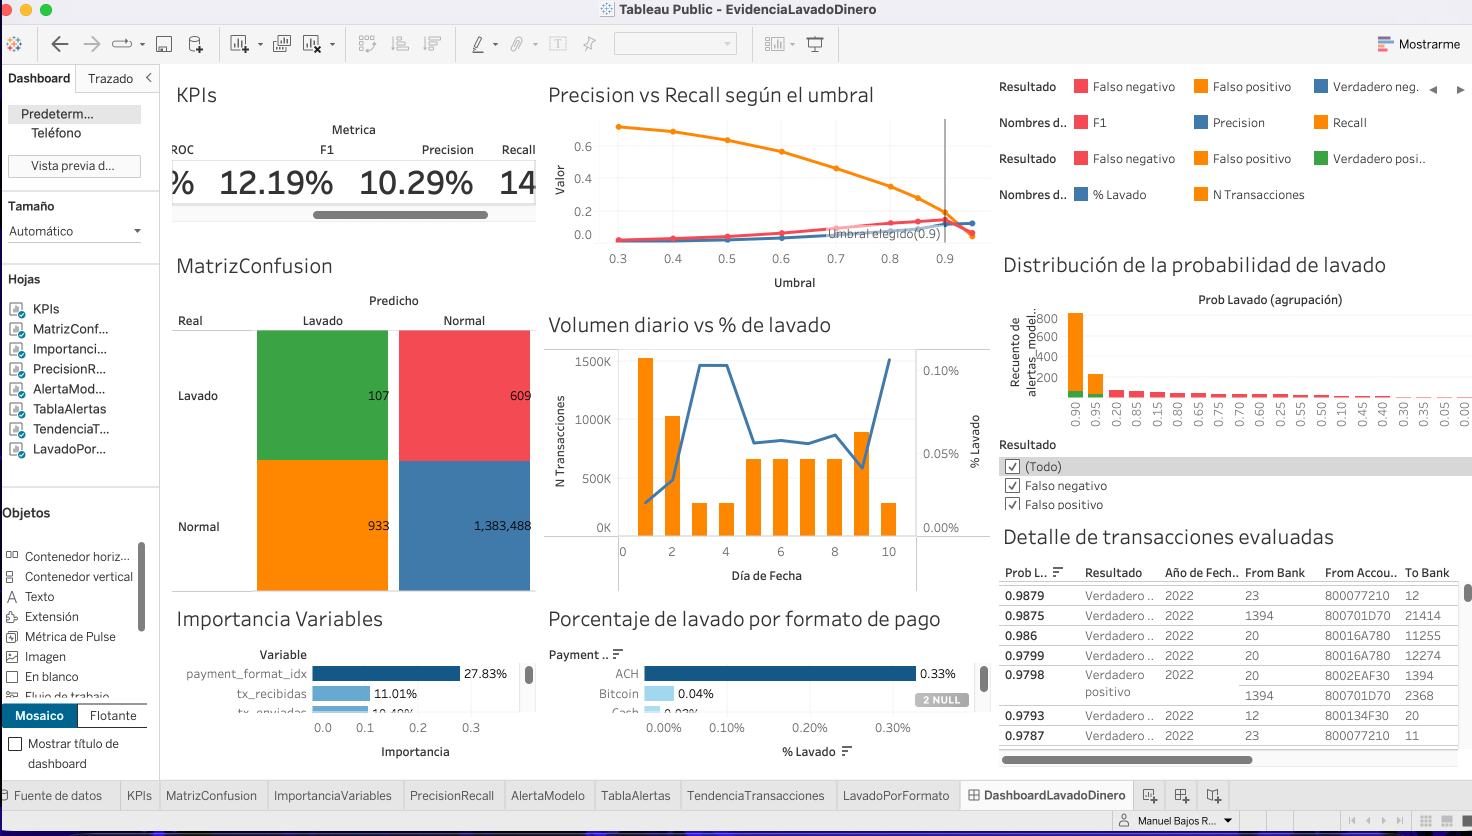

**Hallazgos del tablero**

1. **ACH concentra el 73% del lavado** (2,611 de 3,565 casos), con una tasa 6 veces mayor al promedio. Wire y Reinvestment no tienen casos.
2. **El lavado es constante, pero el volumen normal no.** Hay entre 291 y 402 transacciones de lavado por día, mientras que el total varía de 1.5 millones (1 de septiembre) a ~283 mil en fines de semana. Por eso la tasa de lavado se duplica en sábado y domingo (≈0.10% contra 0.02–0.06% entre semana).
3. **Por hora** (calculado con `resumen_transacciones`), la tasa más alta está entre las 11 y las 16 h (0.066–0.070%). La medianoche tiene el mayor volumen (869 mil transacciones, probablemente pagos programados) y la tasa más baja (0.015%).
4. **Del 11 al 17 de septiembre casi solo hay lavado** (223 transacciones, 60% de lavado), un efecto de la simulación. En la gráfica por día se filtra hasta el 10 de septiembre para no distorsionar la tendencia.
5. **Modelo:** de 1,040 alertas, 107 fueron lavado real. La curva por umbral muestra el compromiso entre detectar más y generar más falsas alarmas. El formato de pago y el comportamiento de las cuentas son las variables que más pesan.

**Nota para leer el tablero:** la gráfica de precision/recall por umbral usa el conjunto de **validación** (con él se eligió el umbral), mientras que los KPIs, la matriz de confusión y la tabla de alertas usan el conjunto de **prueba**. Por eso con umbral 0.9 la gráfica muestra 546 alertas y la matriz 1,040: son conjuntos distintos (692 mil y 1.38 millones de transacciones).

### 10.1 Decisiones que apoya el tablero

El tablero está pensado para un equipo de cumplimiento que revisa alertas de lavado:

| Pregunta del equipo | Dónde se responde | Decisión |
|---|---|---|
| ¿Qué tipo de transacción vigilar más? | % de lavado por formato de pago | Priorizar **ACH**: su tasa (0.33%) es unas 9 veces la del siguiente formato. Wire y Reinvestment se pueden revisar con menos prioridad. |
| ¿Cuándo reforzar el monitoreo? | Volumen diario vs % de lavado | En **fines de semana** la proporción de lavado se duplica, así que conviene revisar con más cuidado aunque haya menos transacciones. |
| ¿Qué alertas revisar primero? | Tabla de detalle (ordenada por probabilidad) y distribución de probabilidad | Revisar en orden de probabilidad: las alertas con probabilidad ≥ 0.98 fueron lavado en 4 de 4 casos, y las de ≥ 0.97 en 59%, contra 10% del total de alertas. |
| ¿Cuántas alertas puede generar el modelo? | Precision vs Recall según el umbral | Elegir el umbral según la capacidad del equipo: con 0.9 hay pocas alertas y más precisas; con 0.5 se detecta el 64% del lavado a cambio de revisar ~1.4% de las transacciones. |
| ¿Qué tan confiable es el modelo? | KPIs y matriz de confusión | El modelo sirve para **priorizar**, no para bloquear transacciones automáticamente: 9 de cada 10 alertas son falsas. |

El filtro **Resultado** permite ver por separado los aciertos (verdaderos positivos), las falsas alarmas (falsos positivos) y el lavado que el modelo no detectó (falsos negativos).

## 11. Conclusiones

**Proceso realizado**

1. Se configuró PySpark 4.0.5 en Google Colab (modo local, 2 núcleos) y se descargó el dataset de IBM para AML desde Kaggle.
2. Se procesaron **6,924,049 transacciones** (`LI-Small`) para entrenar y evaluar, y **5,078,336** más (`HI-Small`) como datos nuevos: más de 12 millones de registros y 1.13 GB de CSV en total.
3. La revisión de calidad mostró datos limpios: 0 nulos, 8 duplicados eliminados, sin montos inválidos y montos consistentes entre pagado y recibido.
4. Se crearon 17 variables, incluidas 5 de comportamiento por cuenta calculadas con agregaciones distribuidas de Spark.
5. Se entrenó un Random Forest con un `Pipeline` de MLlib, balanceando el entrenamiento (undersampling 1:10) y eligiendo hiperparámetros con validación cruzada de 5 folds. Se probaron 4 combinaciones y la mejor fue 100 árboles con profundidad 12.
6. Se eligió el umbral de decisión en un conjunto de validación y se evaluó en un conjunto de prueba con la distribución real.
7. Se exportaron agregados a CSV y se construyó un tablero en Tableau Public.

**Resultados**

| Métrica | Prueba (`LI-Small`) | Datos nuevos (`HI-Small`) |
|---|---|---|
| AUC-ROC | 0.972 | 0.978 |
| AUC-PR | 0.049 (≈ 95× el azar) | 0.099 |
| Precision (umbral 0.9) | 10.3% | 17.0% |
| Recall (umbral 0.9) | 14.9% | 13.4% |
| F1 | 0.122 | 0.150 |

**Conclusiones**

* **La accuracy engaña con clases desbalanceadas.** Solo el 0.05% de las transacciones son lavado. La primera versión del modelo tenía 99.95% de accuracy y no detectaba ningún caso. La versión final tiene una accuracy ligeramente menor (99.89%), pero sí detecta lavado.
* **El modelo es útil como herramienta de priorización, no como clasificador automático.** Ordena muy bien las transacciones por riesgo (AUC-ROC de 0.97): sus alertas tienen unas 200 veces más probabilidad de ser lavado que una transacción al azar, y sus 10 transacciones más sospechosas en datos nuevos fueron todas lavado. Aun así, la mayoría de las alertas son falsas, como ocurre en los sistemas reales de prevención de lavado.
* **Generaliza:** en `HI-Small`, una simulación distinta que nunca vio, obtuvo resultados iguales o mejores.
* **El formato de pago (ACH) y el comportamiento de las cuentas** son las señales más fuertes. El monto, la moneda y la hora pesan menos.
* **El procesamiento escala:** Spark limpió, transformó y agregó 12 millones de transacciones en una máquina de 2 núcleos. Muestrear el entrenamiento y agregar los datos antes de llevarlos a pandas o a Tableau fue lo que lo hizo viable (sección 9.1).
* **El umbral es una decisión de negocio:** con 0.9 se generan pocas alertas más precisas; con 0.5 se detecta el 64% del lavado a cambio de revisar más transacciones.

**Limitaciones y mejoras**

* El lavado se define por **patrones entre varias transacciones** (fan-out, fan-in, ciclos), y aquí cada transacción se clasifica casi de forma aislada. La mejora principal sería agregar variables de grafo, por ejemplo con GraphFrames: ciclos, cadenas de transferencias o cuentas intermediarias.
* Las variables por cuenta usan todo el periodo. En producción habría que calcularlas solo con el historial anterior a cada transacción.
* Se podría probar `GBTClassifier`, usar más transacciones normales en el entrenamiento, eliminar `monto_redondo` (importancia 0) o entrenar con `LI-Medium` (~31 millones de filas) con más memoria.